# Proyek Analisis Data: Olist Brazilian E-Commerce Dataset
- **Nama:** Andika Faliyastats Yunus
- **Email:** andikaifal222@gmail.com
- **ID Dicoding:** andika_f_y

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan pendapatan (revenue) tertinggi dan berapa persen kontribusinya terhadap total pendapatan Olist selama periode Januari 2017 - Agustus 2018?
- **Pertanyaan 2:** Apakah keterlambatan pengiriman menurunkan kepuasan pelanggan, diukur dari selisih rata-rata review score antara pesanan yang terlambat dan pesanan yang tepat waktu, selama periode Januari 2017 - Agustus 2018?

**Pemenuhan kerangka SMART pada kedua pertanyaan:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
| --- | --- | --- |
| **Specific** | Fokus pada satu topik: kategori produk (`product_category_name_english`) terhadap nilai pendapatan (`price`) | Fokus pada satu topik: keterlambatan pengiriman (`delay_days`) terhadap kepuasan pelanggan (`review_score`) |
| **Measurable** | Diukur dengan total pendapatan dalam BRL dan persentase kontribusinya terhadap total | Diukur dengan rata-rata `review_score` skala 1-5 dan selisih poin antara pesanan terlambat dan tepat waktu |
| **Action-Oriented** | Menentukan prioritas kategori untuk alokasi stok, kurasi seller, dan slot promosi berbayar | Menentukan prioritas perbaikan SLA logistik serta kebijakan kompensasi untuk pesanan terlambat |
| **Relevant** | Pendapatan adalah tujuan utama bisnis e-commerce | Kepuasan pelanggan menentukan retensi dan pendapatan berulang |
| **Time-bound** | Periode Januari 2017 - Agustus 2018 | Periode Januari 2017 - Agustus 2018 |

Kedua pertanyaan ini dijawab melalui tahap **Exploratory Data Analysis**, divisualisasikan pada tahap **Visualization & Explanatory Analysis**, lalu disimpulkan pada bagian **Conclusion & Recommendation**.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
!kaggle datasets download -d olistbr/brazilian-ecommerce

Dataset URL: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
License(s): CC-BY-NC-SA-4.0
100% 42.6M/42.6M [00:00<00:00, 140MB/s]



In [3]:
!unzip -o brazilian-ecommerce.zip -d ./data

Archive:  brazilian-ecommerce.zip
  inflating: ./data/olist_customers_dataset.csv  
  inflating: ./data/olist_geolocation_dataset.csv  
  inflating: ./data/olist_order_items_dataset.csv  
  inflating: ./data/olist_order_payments_dataset.csv  
  inflating: ./data/olist_order_reviews_dataset.csv  
  inflating: ./data/olist_orders_dataset.csv  
  inflating: ./data/olist_products_dataset.csv  
  inflating: ./data/olist_sellers_dataset.csv  
  inflating: ./data/product_category_name_translation.csv  


## Data Wrangling

### Gathering Data

#### Load Dataset Olist

Dataset yang digunakan adalah **Brazilian E-Commerce Public Dataset by Olist** (`olistbr/brazilian-ecommerce`). Kesembilan berkas CSV dimuat dari folder `data/` menggunakan `pandas.read_csv()`, lalu dikumpulkan ke dalam satu dictionary `dataframes` agar struktur setiap tabel dapat diperiksa sekaligus.

In [4]:
orders       = pd.read_csv("data/olist_orders_dataset.csv")
order_items  = pd.read_csv("data/olist_order_items_dataset.csv")
customers    = pd.read_csv("data/olist_customers_dataset.csv")
reviews      = pd.read_csv("data/olist_order_reviews_dataset.csv")
payments     = pd.read_csv("data/olist_order_payments_dataset.csv")
products     = pd.read_csv("data/olist_products_dataset.csv")
sellers      = pd.read_csv("data/olist_sellers_dataset.csv")
geolocation  = pd.read_csv("data/olist_geolocation_dataset.csv")
category_tr  = pd.read_csv("data/product_category_name_translation.csv")

In [5]:
dataframes = {
    "orders": orders,
    "order_items": order_items,
    "customers": customers,
    "reviews": reviews,
    "payments": payments,
    "products": products,
    "sellers": sellers,
    "geolocation": geolocation,
    "category_tr": category_tr,
}

for name, df in dataframes.items():
    print(f"{name:15s} {df.shape}")

orders          (99441, 8)
order_items     (112650, 7)
customers       (99441, 5)
reviews         (99224, 7)
payments        (103886, 5)
products        (32951, 9)
sellers         (3095, 4)
geolocation     (1000163, 5)
category_tr     (71, 2)


**Insight - Gathering Data:**

- Dataset yang digunakan adalah **Brazilian E-Commerce Public Dataset by Olist** yang terdiri dari **9 tabel** dan saling terhubung melalui kunci relasi (`order_id`, `customer_id`, `product_id`, `seller_id`). Karena seluruh tabel berasal dari satu basis data yang sama, hasil analisis dari tabel yang berbeda tetap dapat dibandingkan secara adil.
- Skala datanya besar dan berjenjang, sehingga cukup untuk menjawab kedua pertanyaan bisnis: `orders` (99.441 baris) dan `customers` (99.441 baris) sebagai tabel transaksi utama, diperkaya `order_items` (112.650 baris) yang menyimpan nilai transaksi per produk sebagai dasar perhitungan pendapatan per kategori, `payments` (103.886 baris), serta `reviews` (99.224 baris) yang menyimpan `review_score` sebagai dasar pengukuran kepuasan pelanggan.
- Tabel dimensi berukuran kecil tetapi krusial: `products` (32.951 baris) sebagai jembatan dari `product_id` ke kategori produk, `sellers` (3.095 baris), dan `category_tr` (hanya 71 baris) yang menerjemahkan nama kategori ke bahasa Inggris agar label visualisasi mudah dibaca.
- `geolocation` memiliki **1.000.163 baris**, jauh lebih besar daripada tabel lain karena berisi titik koordinat per kode pos. Tabel ini **tidak dipakai** pada analisis karena kedua pertanyaan bisnis tidak menyangkut aspek spasial, sehingga dibiarkan sebagai data mentah agar proses tidak memberatkan komputasi.
- Seluruh tabel dimuat ke dalam satu dictionary `dataframes` dan diperiksa dengan `.shape`, sehingga proporsi antar tabel langsung terlihat. Temuan pada tahap ini menjadi dasar pada tahap **Assessing Data** untuk menentukan tabel mana yang benar-benar perlu dibersihkan.

### Assessing Data

#### Identifying Problem: Missing Value, Duplikasi Review, dan Tipe Data Salah

Pemeriksaan difokuskan pada tiga hal: jumlah *missing value* (`isna().sum()`), jumlah baris duplikat (`duplicated().sum()`), serta perbandingan jumlah baris dengan jumlah `order_id` unik untuk mendeteksi duplikasi pada tingkat entitas, bukan hanya pada tingkat baris.

In [6]:
print("Missing values order")
print(orders.isna().sum())

print("\nMissing values di products")
print(products.isna().sum())

print("\nMissing values di reviews")
print(reviews.isna().sum())

Missing values order
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values di products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Missing values di reviews
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [7]:
print(f"Duplikat baris pada orders: {orders.duplicated().sum()}")
print(f"Duplikat baris pada reviews: {reviews.duplicated().sum()}")
print(f"\nJumlah total baris di reviews: {len(reviews)}")
print(f"Jumlah unique order_id di reviews: {reviews['order_id'].nunique()}")

Duplikat baris pada orders: 0
Duplikat baris pada reviews: 0

Jumlah total baris di reviews: 99224
Jumlah unique order_id di reviews: 98673


**Steps to Take:**
1. **Missing Values pada Kategori Produk:** Terdapat 610 baris di tabel `products` yang tidak memiliki `product_category_name`.
   *Solusi:* Mengisi nilai yang kosong dengan kategori `"unknown"` agar data tidak terbuang saat analisis pendapatan.
2. **Duplikasi Review (Multiple Reviews per Order):** Terdapat 551 pesanan yang memiliki lebih dari satu review.
   *Solusi:* Mengambil satu review saja per `order_id` (review dengan tanggal pembuatan terbaru) agar perhitungan rata-rata `review_score` tidak bias.
3. **Tipe Data Tanggal:** Kolom-kolom waktu pada tabel `orders` masih berformat string (`object`).
   *Solusi:* Mengonversinya menjadi tipe `datetime64`.
4. **Filtering Data:** Analisis dibatasi pada periode Jan 2017 - Agu 2018 dan hanya untuk pesanan yang statusnya `delivered`.

**Insight - Assessing Data:**

- Dari empat potensi masalah yang diperiksa, ditemukan **tiga masalah nyata** yang harus ditangani: *missing value*, *duplikasi pada tingkat entitas*, dan *tipe data tidak tepat*.
- **Missing value** terkonsentrasi pada kolom yang memang bersifat opsional atau bergantung pada proses bisnis. Di `orders`, `order_delivered_customer_date` kosong pada **2.965 baris** dan `order_approved_at` kosong pada **160 baris**; di `products`, `product_category_name` kosong pada **610 baris** (ditambah 2 baris tanpa berat dan dimensi produk); di `reviews`, komentar teks kosong secara masif, yaitu `review_comment_title` **87.656 baris** dan `review_comment_message` **58.247 baris**.
- **Duplikasi tidak terjadi pada tingkat baris** (`orders` dan `reviews` masing-masing 0 baris duplikat), **tetapi terjadi pada tingkat entitas**: 99.224 baris review hanya mencakup **98.673 `order_id` unik**, artinya ada **551 pesanan yang memiliki lebih dari satu review**. Inilah sumber bias utama apabila rata-rata `review_score` dihitung tanpa deduplikasi, karena satu pesanan dapat dihitung lebih dari sekali.
- **Tipe data tidak tepat** ditemukan pada 5 kolom tanggal di `orders` yang masih bertipe `object` (string). Selama masih berupa string, operasi aritmetika waktu seperti selisih hari antara tanggal tiba dan tanggal estimasi tidak dapat dilakukan.
- **Kesimpulan tahap assessing:** tidak semua *missing value* harus diimputasi. Nilai kosong pada kolom komentar review dan pada tanggal pengiriman bersifat informatif karena mewakili pesanan yang belum selesai atau pelanggan yang memang tidak menulis komentar, sehingga dibiarkan apa adanya. Sebaliknya, kategori produk, duplikasi review, dan tipe data tanggal **wajib diperbaiki** karena langsung memengaruhi perhitungan pendapatan per kategori dan rata-rata `review_score`.

### Cleaning Data

#### Fixing Problem: Imputasi Kategori, Deduplikasi Review, Konversi Tipe Data, dan Filtering

Setiap masalah yang ditemukan pada tahap *Assessing Data* diperbaiki sesuai solusi yang telah ditetapkan, kemudian hasilnya digabungkan menjadi dua tabel analisis (`df_q1` dan `df_q2`) yang siap dieksplorasi.

In [17]:
products['product_category_name'] = products['product_category_name'].fillna('unknown')

reviews_sorted = reviews.sort_values(by='review_creation_date', ascending=False)
reviews_cleaned = reviews_sorted.drop_duplicates(subset='order_id', keep='first')

date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

orders_delivered = orders[orders['order_status'] == 'delivered'].copy()
orders_cleaned = orders_delivered[
    (orders_delivered['order_purchase_timestamp'] >= '2017-01-01') &
    (orders_delivered['order_purchase_timestamp'] <= '2018-08-31')
].copy()

df_q1 = pd.merge(orders_cleaned, order_items[['order_id', 'product_id', 'price']], on='order_id', how='inner')
df_q1 = pd.merge(df_q1, products[['product_id', 'product_category_name']], on='product_id', how='left')
df_q1 = pd.merge(df_q1, category_tr, on='product_category_name', how='left')
df_q1['product_category_name_english'] = df_q1['product_category_name_english'].fillna('unknown')

df_q2 = pd.merge(orders_cleaned, reviews_cleaned[['order_id', 'review_score', 'review_creation_date']], on='order_id', how='inner')
df_q2['delay_days'] = (df_q2['order_delivered_customer_date'] - df_q2['order_estimated_delivery_date']).dt.days
df_q2 = df_q2.dropna(subset=['delay_days'])
df_q2['delivery_status'] = df_q2['delay_days'].apply(lambda x: 'Late' if x > 0 else 'On Time')

print(f"Jumlah orders awal: {len(orders)}")
print(f"Jumlah orders delivered: {len(orders_delivered)}")
print(f"Jumlah orders final (Jan 2017 - Agu 2018): {len(orders_cleaned)}")
print(f"Jumlah reviews awal: {len(reviews)} | final: {len(reviews_cleaned)}")
print(f"Missing product_category_name setelah cleaning: {products['product_category_name'].isna().sum()}")
print(f"Bentuk df_q1: {df_q1.shape} | Bentuk df_q2: {df_q2.shape}")

Jumlah orders awal: 99441
Jumlah orders delivered: 96478
Jumlah orders final (Jan 2017 - Agu 2018): 96211
Jumlah reviews awal: 99224 | final: 98673
Missing product_category_name setelah cleaning: 0
Bentuk df_q1: (109880, 12) | Bentuk df_q2: (95560, 12)


**Insight - Cleaning Data:**
- Setelah cleaning, missing value product_category_name = 0 dan reviews tersisa 98.673 baris (tepat satu review per order), sehingga rata-rata review score tidak lagi bias.
- Filter status delivered + periode Jan 2017–Agu 2018 menyisakan 96.211 pesanan dari 99.441; pengurangan ini adalah konsekuensi batasan bisnis, bukan kehilangan data.
- Hasil merge siap analisis: df_q1 109.880 baris (level item, untuk revenue per kategori) dan df_q2 95.560 baris (level pesanan, lengkap dengan delay_days dan delivery_status).

## Exploratory Data Analysis (EDA)

### Explore Revenue per Kategori dan Dampak Keterlambatan terhadap Review Score

Eksplorasi dilakukan dengan dua cara: **agregasi `groupby`** untuk meringkas data ke level kategori produk dan level status pengiriman, serta **statistik deskriptif** (`mean` dan `count`) untuk melihat arah serta besaran perbedaan antar kelompok.

In [19]:
#Q1
revenue_per_category = df_q1.groupby('product_category_name_english')['price'].sum().reset_index()
revenue_per_category.rename(columns={'price': 'total_revenue'}, inplace=True)
revenue_per_category = revenue_per_category.sort_values(by='total_revenue', ascending=False).reset_index(drop=True)
total_revenue_all = revenue_per_category['total_revenue'].sum()
revenue_per_category['contribution_pct'] = (revenue_per_category['total_revenue'] / total_revenue_all) * 100

top_15_categories = revenue_per_category.head(15)
print("Top 15 Kategori Produk dengan Revenue Tertinggi:")
display(top_15_categories)

Top 15 Kategori Produk dengan Revenue Tertinggi:


,product_category_name_english,total_revenue,contribution_pct
0,health_beauty,1229557.50,9.328237
1,watches_gifts,1163465.91,8.826823
2,bed_bath_table,1022955.77,7.760820
3,sports_leisure,952840.40,7.228878
4,computers_accessories,888055.59,6.737378
5,furniture_decor,706237.17,5.357983
6,housewares,614341.62,4.660802
7,cool_stuff,609158.00,4.621476
8,auto,577838.39,4.383865
9,garden_tools,469135.40,3.559172


In [20]:
#Q2
avg_score_status = df_q2.groupby('delivery_status')['review_score'].mean().reset_index()
print("Rata-rata Review Score berdasarkan Status Pengiriman:")
display(avg_score_status)

def categorize_delay(days):
    if days <= 0:
        return 'Tepat Waktu / Lebih Cepat'
    elif days <= 3:
        return 'Telat 1-3 Hari'
    elif days <= 7:
        return 'Telat 4-7 Hari'
    else:
        return 'Telat > 7 Hari'

df_q2['delay_category'] = df_q2['delay_days'].apply(categorize_delay)

category_order = ['Tepat Waktu / Lebih Cepat', 'Telat 1-3 Hari', 'Telat 4-7 Hari', 'Telat > 7 Hari']
df_q2['delay_category'] = pd.Categorical(df_q2['delay_category'], categories=category_order, ordered=True)

avg_score_delay = df_q2.groupby('delay_category', observed=False).agg(
    avg_review_score=('review_score', 'mean'),
    total_orders=('order_id', 'count')
).reset_index()

print("\nRata-rata Review Score berdasarkan Kategori Keterlambatan:")
display(avg_score_delay)

Rata-rata Review Score berdasarkan Status Pengiriman:


,delivery_status,review_score
0,Late,2.270931
1,On Time,4.291101



Rata-rata Review Score berdasarkan Kategori Keterlambatan:


,delay_category,avg_review_score,total_orders
0,Tepat Waktu / Lebih Cepat,4.291101,89182
1,Telat 1-3 Hari,3.290654,1851
2,Telat 4-7 Hari,2.104691,1748
3,Telat > 7 Hari,1.696294,2779


**Insight - Exploratory Data Analysis:**

- **Pertanyaan 1 (pendapatan per kategori):** distribusi pendapatan bersifat *right-skewed*, yaitu beberapa kategori menyumbang porsi besar sementara ekor panjang kategori kecil menyumbang sangat sedikit. `health_beauty` memuncaki daftar dengan total **BRL 1.229.558 (sekitar 9,3%)**, diikuti `watches_gifts` (sekitar 8,8%) dan `bed_bath_table` (sekitar 7,8%), sehingga **5 kategori teratas menyumbang hampir 40%** dari total pendapatan. Tidak ada satu kategori yang mendominasi secara ekstrem di atas 50%, sehingga risiko ketergantungan pada satu kategori relatif rendah.
- **Pertanyaan 2 (dampak keterlambatan):** agregasi rata-rata `review_score` per `delivery_status` menghasilkan **4,29** untuk pesanan *On Time* berbanding **2,27** untuk pesanan *Late*, yaitu selisih **2,02 poin** pada skala 1-5. Arah hubungannya konsisten: semakin parah keterlambatan, semakin rendah skornya, yaitu *Telat 1-3 Hari* **3,29**, *Telat 4-7 Hari* **2,10**, dan *Telat > 7 Hari* **1,70**.
- **Temuan yang tidak terlihat dari status biner:** penurunan skor terbesar tidak terjadi pada lompatan dari tepat waktu ke terlambat, melainkan pada lompatan dari *Telat 1-3 Hari* ke *Telat 4-7 Hari* yang turun sekitar **1,19 poin**. Artinya pelanggan masih relatif memaklumi keterlambatan singkat, tetapi toleransinya runtuh begitu pesanan melewati sepekan.
- **Implikasi analitis:** keterlambatan adalah variabel yang layak menjadi prioritas perbaikan operasional, dan pengelompokan tingkat keparahan (`delay_category`) jauh lebih informatif daripada status biner `Late` atau `On Time`. Kedua temuan inilah yang divisualisasikan pada tahap berikutnya.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Kategori produk apa yang menghasilkan pendapatan (revenue) tertinggi dan berapa persen kontribusinya terhadap total pendapatan Olist selama periode Januari 2017 - Agustus 2018?

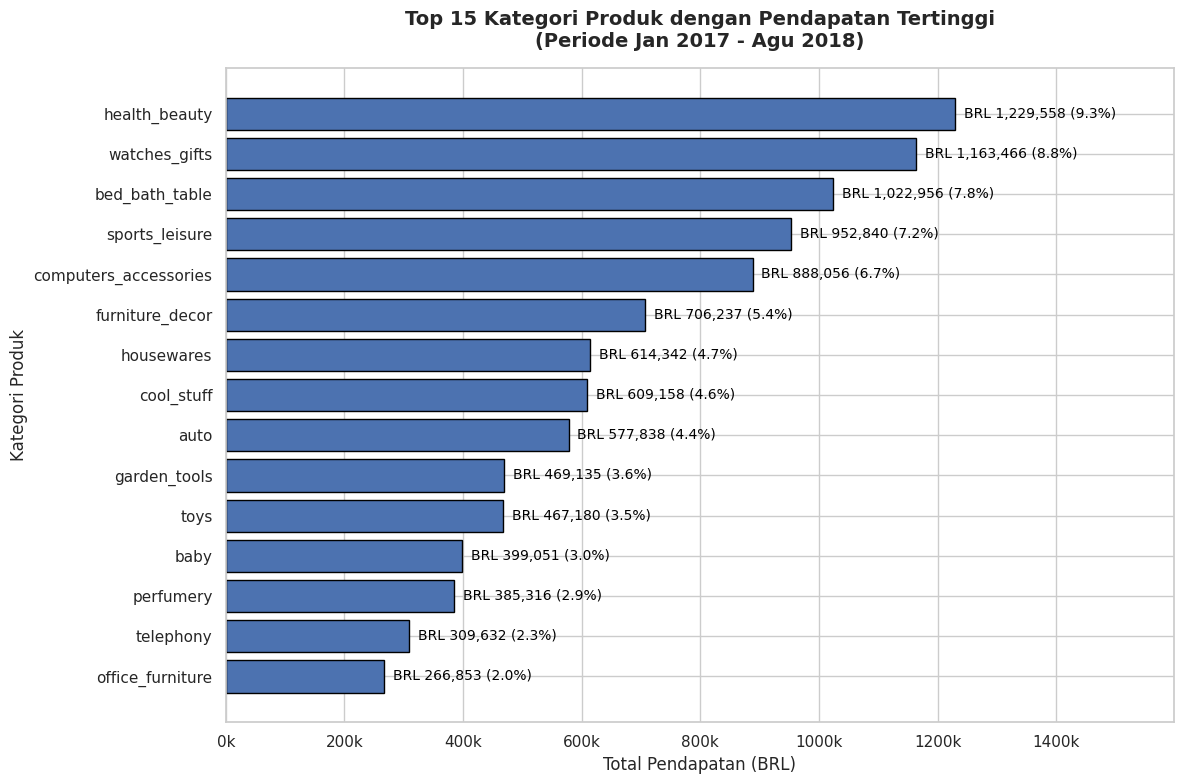

In [11]:
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

plot_data = top_15_categories.sort_values(by='total_revenue', ascending=True)

bars = plt.barh(plot_data['product_category_name_english'],
                plot_data['total_revenue'],
                color='#4C72B0', edgecolor='black')

for i, bar in enumerate(bars):
    width = bar.get_width()
    pct = plot_data.iloc[i]['contribution_pct']
    plt.text(width + 15000, bar.get_y() + bar.get_height()/2,
             f'BRL {width:,.0f} ({pct:.1f}%)',
             va='center', fontsize=10, color='black')

plt.title('Top 15 Kategori Produk dengan Pendapatan Tertinggi\n(Periode Jan 2017 - Agu 2018)',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Pendapatan (BRL)', fontsize=12)
plt.ylabel('Kategori Produk', fontsize=12)
plt.xlim(0, plot_data['total_revenue'].max() * 1.30)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x/1000:.0f}k"))
plt.tight_layout()
plt.show()

### Pertanyaan 2:
Apakah keterlambatan pengiriman menurunkan kepuasan pelanggan, diukur dari selisih rata-rata review score antara pesanan yang terlambat dan pesanan yang tepat waktu, selama periode Januari 2017 - Agustus 2018?

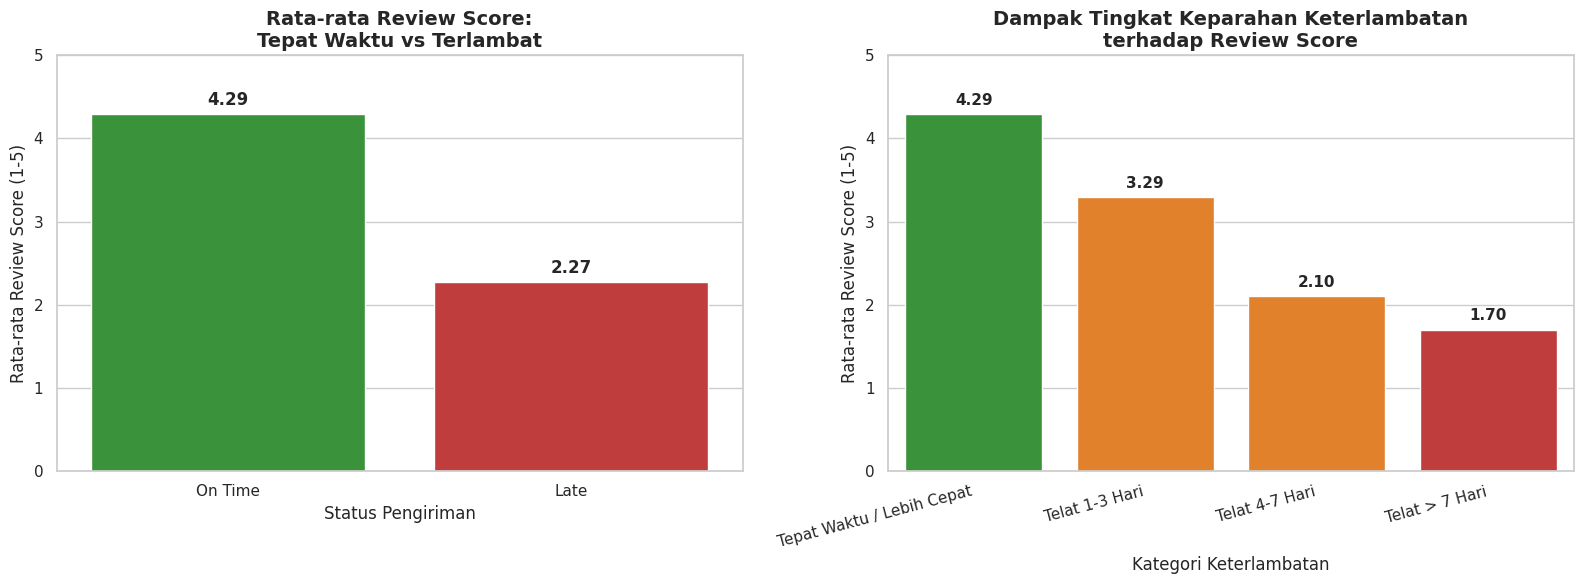

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

colors_status = {'On Time': '#2ca02c', 'Late': '#d62728'}
sns.barplot(
    x='delivery_status',
    y='review_score',
    data=avg_score_status,
    palette=colors_status,
    order=['On Time', 'Late'],
    ax=axes[0],
    hue='delivery_status',
    legend=False
)

axes[0].set_title('Rata-rata Review Score:\nTepat Waktu vs Terlambat', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Status Pengiriman', fontsize=12)
axes[0].set_ylabel('Rata-rata Review Score (1-5)', fontsize=12)
axes[0].set_ylim(0, 5)

for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center',
                     xytext=(0, 10), textcoords='offset points',
                     fontsize=12, fontweight='bold')

colors_delay = ['#2ca02c', '#ff7f0e', '#ff7f0e', '#d62728']
sns.barplot(
    x='delay_category',
    y='avg_review_score',
    data=avg_score_delay,
    palette=colors_delay,
    ax=axes[1],
    hue='delay_category',
    legend=False
)

axes[1].set_title('Dampak Tingkat Keparahan Keterlambatan\nterhadap Review Score', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Kategori Keterlambatan', fontsize=12)
axes[1].set_ylabel('Rata-rata Review Score (1-5)', fontsize=12)
axes[1].set_ylim(0, 5)
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=15, ha='right')

for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center',
                     xytext=(0, 10), textcoords='offset points',
                     fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight - Visualization & Explanatory Analysis:**

- **Visualisasi Pertanyaan 1** berupa *horizontal bar chart* Top 15 kategori yang diurutkan menaik, sehingga kategori berpendapatan tertinggi berada di posisi paling atas dan mata pembaca langsung tertuju pada pesan utama. Setiap batang diberi label **nilai absolut sekaligus persentase kontribusi**, sehingga audiens tidak perlu menebak besaran maupun proporsinya. Sumbu X diberi ruang tambahan sebesar 1,3 kali nilai maksimum agar label tidak terpotong, dan karena batang horizontal berpangkal pada nol, panjang batang tetap proporsional terhadap nilai.
- **Pesan dari Pertanyaan 1:** pendapatan Olist terkonsentrasi pada segmen gaya hidup dan rumah tangga, yaitu `health_beauty` (BRL 1.229.558 atau 9,3%), `watches_gifts` (8,8%), dan `bed_bath_table` (7,8%), dengan 5 kategori teratas menyumbang hampir 40% total pendapatan namun tanpa dominasi tunggal.
- **Visualisasi Pertanyaan 2** memakai dua panel sejajar dalam satu figur: panel kiri membandingkan *On Time* dengan *Late* menggunakan warna semantik (hijau untuk kondisi aman dan merah untuk kondisi bermasalah), sedangkan panel kanan menampilkan gradasi keparahan keterlambatan dengan **skala Y yang sama (0-5)** sehingga perbandingan antar panel menjadi adil. Setiap batang diberi anotasi nilai rata-rata agar pembaca tidak bergantung pada pembacaan garis grid.
- **Pesan dari Pertanyaan 2:** kepuasan pelanggan jatuh dari **4,29 menjadi 2,27** atau selisih 2,02 poin ketika pesanan terlambat, dan terus menurun seiring keparahannya, yaitu 3,29 untuk telat 1-3 hari, 2,10 untuk telat 4-7 hari, hingga 1,70 untuk telat lebih dari 7 hari. Visual ini sekaligus menunjukkan bahwa **durasi keterlambatan, bukan sekadar status terlambat, adalah penentu utama kepuasan pelanggan**.

## Analisis Lanjutan (Opsional)

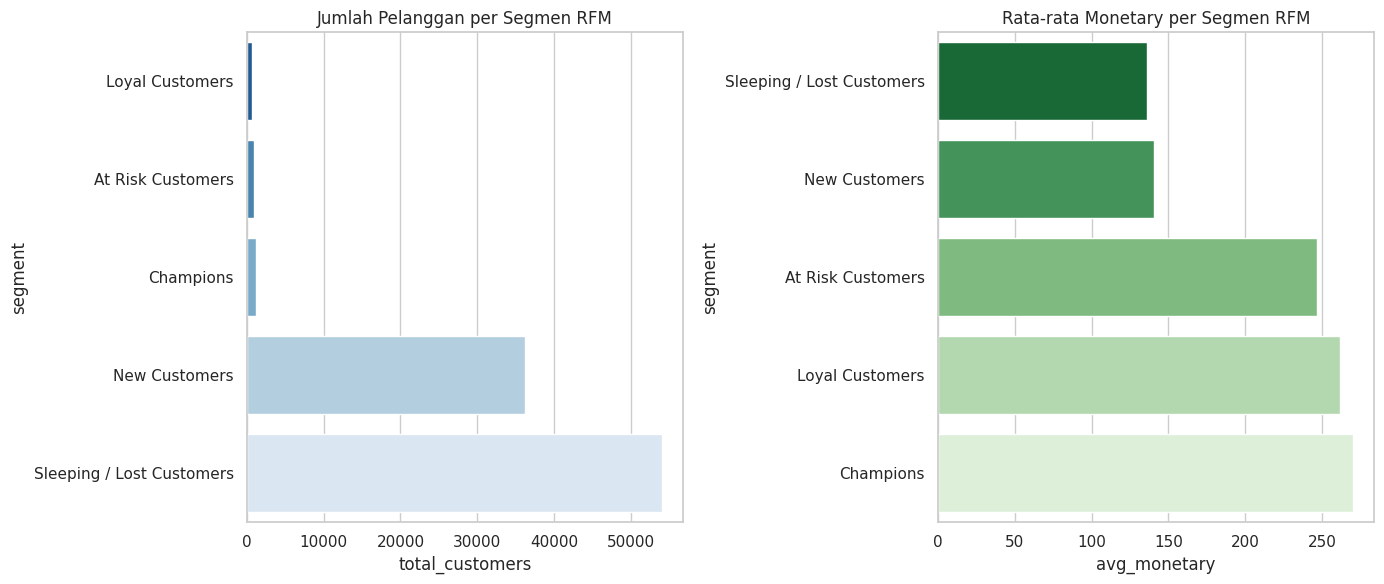

In [14]:
# Advanced Analysis: RFM Analysis

df_rfm_base = pd.merge(
    df_q1[['order_id', 'customer_id', 'order_purchase_timestamp', 'price']],
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id', how='left'
)
rfm = df_rfm_base.groupby('customer_unique_id').agg(
    last_purchase=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum')
).reset_index()

reference_date = df_rfm_base['order_purchase_timestamp'].max()
rfm['recency'] = (reference_date - rfm['last_purchase']).dt.days

rfm['R_bin'] = pd.qcut(rfm['recency'], q=5, duplicates='drop')
rfm['M_bin'] = pd.qcut(rfm['monetary'], q=5, duplicates='drop')
k_r = rfm['R_bin'].cat.categories.size
rfm['R_score'] = k_r - rfm['R_bin'].cat.codes
rfm['M_score'] = rfm['M_bin'].cat.codes + 1
rfm['F_score'] = rfm['frequency'].apply(lambda f: 1 if f==1 else (3 if f==2 else (4 if f==3 else 5)))

def segment_rfm(row):
    if row['R_score'] >= 4 and row['F_score'] >= 2: return 'Champions'
    elif row['R_score'] == 3 and row['F_score'] >= 2: return 'Loyal Customers'
    elif row['R_score'] >= 4 and row['F_score'] == 1: return 'New Customers'
    elif row['R_score'] <= 2 and row['F_score'] >= 2: return 'At Risk Customers'
    else: return 'Sleeping / Lost Customers'

rfm['segment'] = rfm.apply(segment_rfm, axis=1)

rfm_summary = rfm.groupby('segment').agg(
    total_customers=('customer_unique_id', 'count'),
    avg_monetary=('monetary', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=rfm_summary.sort_values('total_customers', ascending=True), x='total_customers', y='segment', hue='segment', palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title('Jumlah Pelanggan per Segmen RFM')
sns.barplot(data=rfm_summary.sort_values('avg_monetary', ascending=True), x='avg_monetary', y='segment', hue='segment', palette='Greens_r', legend=False, ax=axes[1])
axes[1].set_title('Rata-rata Monetary per Segmen RFM')
plt.tight_layout()
plt.show()

**Insight - Analisis Lanjutan (RFM):**

- Hasil segmentasi memperlihatkan pola khas *marketplace*: mayoritas pelanggan, yaitu **sekitar 97%**, berada pada segmen pembeli satu kali yang tercakup dalam **Sleeping / Lost Customers** dan **New Customers**. Basis pelanggan Olist sangat lebar tetapi sangat dangkal, sehingga masalah utamanya bukan sekadar akuisisi, melainkan **mengonversi pembelian pertama menjadi pembelian kedua**.
- Sebaliknya, segmen pelanggan berulang (**Champions**, **Loyal Customers**, dan **At Risk Customers**) jumlahnya sangat kecil, namun rata-rata nilai belanja atau *monetary* mereka **hampir dua kali lipat** dibandingkan pembeli satu kali. Artinya sebagian kecil pelanggan menyumbang nilai yang jauh lebih besar, sehingga pelanggan setia adalah aset yang paling layak dijaga.
- Pola ini memperkuat temuan tahap sebelumnya: karena pendapatan terkonsentrasi pada beberapa kategori dan kepuasan hancur oleh keterlambatan, pelanggan yang pernah mengalami keterlambatan panjang berisiko tinggi berpindah ke segmen **At Risk** atau **Lost**. Perbaikan SLA logistik karenanya bukan hanya isu kepuasan, tetapi juga **strategi retensi pelanggan**.
- **Dampak terhadap pengambilan keputusan:** anggaran promosi sebaiknya tidak dibagi rata. Prioritas diberikan pada program *win-back* untuk **At Risk Customers** dan program *loyalty* atau *early access* untuk **Champions**, sementara **New Customers** didorong dengan insentif pembelian kedua dalam 30 sampai 90 hari.

## Conclusion & Recommendation

1. **Conclusion Pertanyaan 1 (Pendapatan Kategori):**
   Kategori produk dengan pendapatan tertinggi adalah **health_beauty** dengan total **BRL 1.229.558 (9,3% dari total pendapatan)**, diikuti oleh **watches_gifts** (8,8%) dan **bed_bath_table** (7,8%). Top 5 kategori menyumbang hampir 40% dari total pendapatan, menunjukkan bahwa pendapatan Olist terkonsentrasi pada beberapa kategori utama gaya hidup dan rumah tangga, tanpa adanya dominasi tunggal yang ekstrem.
   
2. **Conclusion Pertanyaan 2 (Dampak Keterlambatan):**
   Keterlambatan pengiriman terbukti **menurunkan kepuasan pelanggan secara signifikan**. Pesanan yang tiba tepat waktu atau lebih cepat memiliki rata-rata review score **4,29**, sedangkan pesanan yang terlambat anjlok ke angka **2,27** (selisih 2,02 poin). Lebih lanjut, tingkat keparahan keterlambatan berkorelasi lurus dengan penurunan skor: telat 1–3 hari (skor 3,29), telat 4–7 hari (skor 2,10), dan telat > 7 hari (skor 1,70).

3. **Conclusion Analisis Lanjutan (RFM):**
   Mayoritas pelanggan (97%) adalah pembeli satu kali (*Sleeping/Lost* dan *New Customers*). Namun, segmen pelanggan berulang yang sangat kecil (*Champions*, *Loyal*, *At Risk*) memberikan kontribusi *monetary* (nilai belanja) hampir dua kali lipat lebih besar dibandingkan pembeli satu kali.


**Rekomendasi Action Item:**

1. **Strategi Inventori & Promosi:** Prioritaskan stok, kurasi seller, dan slot promosi berbayar pada kategori *health_beauty*, *watches_gifts*, dan *bed_bath_table*. Gunakan strategi *bundling* dengan kategori peringkat menengah (seperti *cool_stuff* atau *toys*) untuk meningkatkan *Average Order Value* (AOV).
2. **Manajemen Logistik & Ekspektasi Pelanggan:**
   - Audit mitra logistik yang sering menyumbang keterlambatan > 7 hari.
   - Terapkan sistem notifikasi proaktif (WhatsApp/Email) yang meminta maaf dan memberikan update ketika pesanan memasuki fase telat 1-3 hari untuk menahan ekspektasi pelanggan.
   - Berikan kompensasi otomatis (seperti voucher diskon untuk pembelian berikutnya) khusus untuk pesanan yang telat > 7 hari guna mencegah *churn* dan ulasan bintang 1.
3. **Program Retensi Berbasis RFM:**
   - **Champions:** Berikan akses *early-bird* ke promo besar (seperti Black Friday/Flash Sale) dan program *loyalty rewards*.
   - **At Risk Customers:** Jalankan *win-back campaign* melalui email marketing personal dengan insentif khusus sebelum mereka benar-benar hilang.
   - **New Customers:** Kirimkan rekomendasi produk terkait (*cross-selling*) dan insentif pembelian kedua yang hanya berlaku selama 30-90 hari setelah transaksi pertama mereka.